In [7]:
# pip install neo4j networkx pandas scipy scikit-learn
from neo4j import GraphDatabase
import pandas as pd
import networkx as nx
import numpy as np
from scipy.sparse import diags
from sklearn.linear_model import LogisticRegression, LinearRegression
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [8]:
uri = "bolt://localhost:7687"
auth = ("neo4j", "password")
driver = GraphDatabase.driver(uri, auth=auth)

print(driver)

Adjacency Matrix A:


,4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,4:b657dce7-b226-409e-98a7-0176a0fab3fd:4,4:b657dce7-b226-409e-98a7-0176a0fab3fd:5,4:b657dce7-b226-409e-98a7-0176a0fab3fd:6,4:b657dce7-b226-409e-98a7-0176a0fab3fd:7
4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,0,0,0,1,0,0,0,0,0,0,0,0,0,1
4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,1,0,0,0,0,0,0,1,0,1,0,1,0,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,0,1,0,0,0,0,0,0,0,1,0,0,0,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,0,0,0,0,0,0,1,0,1,0,0,0,0,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,0,0,0,0,0,1,0,0,0,0,0,0,1,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,0,0,1,0,1,0,0,0,0,0,0,0,0,0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,0,0,0,0,0,1,0,0,0,0,0,0,0,1
4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,0,0,1,1,0,0,0,0,0,0,0,0,0,0


Degree Matrix D:


,4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,4:b657dce7-b226-409e-98a7-0176a0fab3fd:4,4:b657dce7-b226-409e-98a7-0176a0fab3fd:5,4:b657dce7-b226-409e-98a7-0176a0fab3fd:6,4:b657dce7-b226-409e-98a7-0176a0fab3fd:7
4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0


Graph Laplacian L = D - A:


,4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,4:b657dce7-b226-409e-98a7-0176a0fab3fd:4,4:b657dce7-b226-409e-98a7-0176a0fab3fd:5,4:b657dce7-b226-409e-98a7-0176a0fab3fd:6,4:b657dce7-b226-409e-98a7-0176a0fab3fd:7
4:b657dce7-b226-409e-98a7-0176a0fab3fd:0,2.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:8,0.0,2.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:10,-1.0,0.0,4.0,0.0,0.0,0.0,0.0,-1.0,0.0,-1.0,0.0,-1.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:1,0.0,-1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:9,0.0,0.0,0.0,0.0,2.0,0.0,0.0,-1.0,0.0,0.0,-1.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:11,0.0,0.0,0.0,0.0,0.0,2.0,-1.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:2,0.0,0.0,0.0,0.0,0.0,-1.0,2.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:13,0.0,0.0,-1.0,0.0,-1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:3,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,-1.0
4:b657dce7-b226-409e-98a7-0176a0fab3fd:12,0.0,0.0,-1.0,-1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0


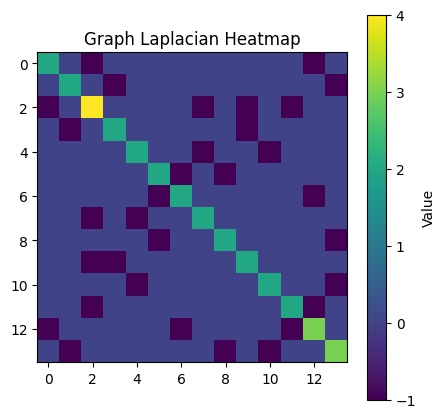

In [9]:
# 1) Pull edges (undirected)
with driver.session() as s:
    df_edges = s.run("""
        MATCH (c:Customer)-[:BOUGHT]-(p:Product)
        RETURN elementId(c) AS src, elementId(p) AS dst
    """).to_df()

# 2) Pull node features/labels (only Customers, for ML)
with driver.session() as s:
    df_nodes = s.run("""
        MATCH (c:Customer)
        RETURN elementId(c) AS nid, c.hv AS hv, c.clv AS clv
    """).to_df()

# 3) Build NetworkX graph
G = nx.from_pandas_edgelist(df_edges, 'src', 'dst', create_using=nx.Graph())

# Add labels/targets as node attributes
nx.set_node_attributes(G, df_nodes.set_index('nid')['hv'].to_dict(),  'hv')
nx.set_node_attributes(G, df_nodes.set_index('nid')['clv'].to_dict(), 'clv')

# 4) Adjacency matrix (SciPy sparse)
A = nx.to_scipy_sparse_array(G, nodelist=sorted(G.nodes()))
# Degree matrix (diagonal of degrees)
deg_vec = np.array([G.degree(n) for n in sorted(G.nodes())])
D = diags(deg_vec)
# (Optional) Graph Laplacian L = D - A
L = D - A

# Convert to dense + DataFrame for pretty display
A_df = pd.DataFrame(A.toarray(), index=G.nodes(), columns=G.nodes())
D_df = pd.DataFrame(D.toarray(), index=G.nodes(), columns=G.nodes())
L_df = pd.DataFrame(L.toarray(), index=G.nodes(), columns=G.nodes())

print("Adjacency Matrix A:")
display(A_df)

print("Degree Matrix D:")
display(D_df)

print("Graph Laplacian L = D - A:")
display(L_df)

# Convert to dense for visualization
L_dense = L.toarray()

plt.figure(figsize=(5,5))
plt.imshow(L_dense, cmap="viridis", interpolation="nearest")
plt.colorbar(label="Value")
plt.title("Graph Laplacian Heatmap")
plt.show()

In [ ]:
# Build a feature matrix X and label y for Customer nodes only
cust_nodes = [n for n, d in G.nodes(data=True) if 'hv' in d]
X = np.array([[G.degree(n)] for n in cust_nodes])   # 1D feature: degree
y = np.array([G.nodes[n]['hv'] for n in cust_nodes])

clf = LogisticRegression().fit(X, y)
print("Train accuracy:", clf.score(X, y))